# Phân cụm seller v3: EDA, K-Means, GMM, DBSCAN

Chạy K-Means, GMM, DBSCAN trên **cùng ma trận 12 đặc trưng v3** để so sánh. Thay đổi so với v2:
- **Bỏ:** `cancel_rate` (88% = 0), `repeat_customer_rate` (84% = 0), `avg_order_value` (tương quan 0,88 với `price_index`).
- **Thêm:** `price_index` (giá so với TB ngành), `freight_per_item` (phí ship/món), `interstate_rate` (tỷ lệ đơn khác bang).

Input: `artifacts/seller_segmentation_v2/seller_features.csv` | Output: `artifacts/seller_clustering_v3/`

In [1]:
import json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt, seaborn as sns, sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INPUT = ROOT / "artifacts/seller_segmentation_v2/seller_features.csv"
OUT = ROOT / "artifacts/seller_clustering_v3"
OUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE, K_RANGE, MIN_SHARE, K_KMEANS = 42, range(2, 11), 0.02, 5
FEATURES = ["order_count", "recency_days", "tenure_days", "late_delivery_rate", "review_score_mean",
            "category_count", "avg_ship_distance_km", "hot_score", "delivery_days_mean",
            "price_index", "freight_per_item", "interstate_rate"]
LOG1P = ["order_count", "recency_days", "delivery_days_mean", "category_count",
         "avg_ship_distance_km", "price_index", "freight_per_item"]  # tenure_days skew=0.08 nên không log
DROPPED = ["cancel_rate", "repeat_customer_rate", "avg_order_value"]
DESCRIBE = ["total_sales", "avg_order_value", "cancel_rate", "repeat_customer_rate",
            "category_hhi", "n_customer_states", "orders_per_active_month"]

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200, "display.max_columns", 40)

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight", dpi=120)
    plt.show()

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}

## 1. Dữ liệu & Cohort
Chỉ đưa vào mô hình seller có `model_eligible = True` (**≥ 3 đơn delivered**) để tránh nhiễu tỷ lệ.

In [2]:
raw = pd.read_csv(INPUT)
assert raw["seller_id"].is_unique
assert all(c in raw for c in FEATURES + DROPPED + DESCRIBE)
df = raw[raw["model_eligible"]].reset_index(drop=True)
print(f"Tổng seller: {len(raw):,} | Cohort mô hình: {len(df):,} | Số cột: {raw.shape[1]}")

cohort = raw.assign(nhom=np.where(raw["model_eligible"], ">= 3 đơn", "< 3 đơn")).groupby("nhom").agg(
    so_seller=("seller_id", "size"), tong_doanh_so=("total_sales", "sum"), don_trung_vi=("order_count", "median"))
cohort["ty_le_seller"] = cohort["so_seller"] / cohort["so_seller"].sum()
cohort["ty_le_doanh_so"] = cohort["tong_doanh_so"] / cohort["tong_doanh_so"].sum()
cohort.round(4)

Tổng seller: 2,970 | Cohort mô hình: 2,129 | Số cột: 82


,so_seller,tong_doanh_so,don_trung_vi,ty_le_seller,ty_le_doanh_so
nhom,,,,,
< 3 đơn,841,264775.66,1.0,0.2832,0.02
>= 3 đơn,2129,12956722.45,12.0,0.7168,0.98


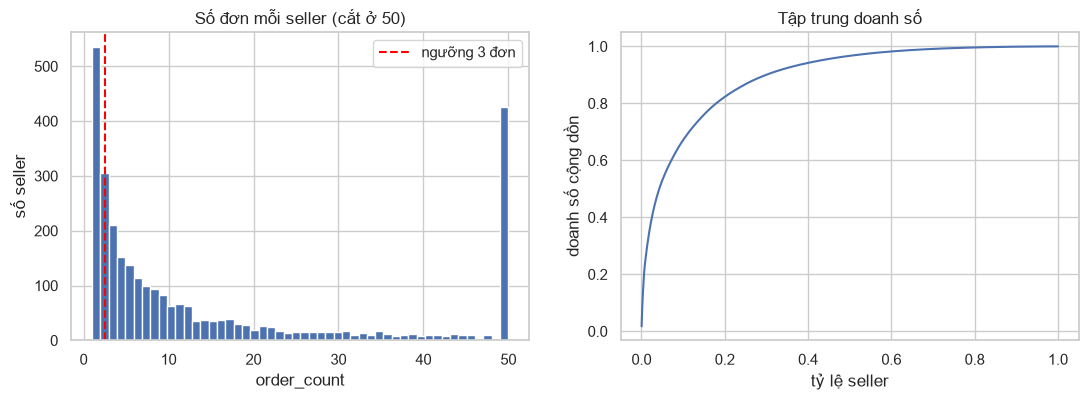

Seller 1 đơn: 18.0% | Top 20% seller chiếm 82.3% doanh số


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(raw["order_count"].clip(upper=50), bins=50, color="#4C72B0")
ax[0].axvline(2.5, color="red", ls="--", label="ngưỡng 3 đơn")
ax[0].set(title="Số đơn mỗi seller (cắt ở 50)", xlabel="order_count", ylabel="số seller"); ax[0].legend()

s = raw["total_sales"].sort_values(ascending=False)
ax[1].plot(np.arange(1, len(s) + 1) / len(s), s.cumsum() / s.sum())
ax[1].set(title="Tập trung doanh số", xlabel="tỷ lệ seller", ylabel="doanh số cộng dồn")
save(fig, "eda_cohort.png")
print(f"Seller 1 đơn: {(raw.order_count == 1).mean():.1%} | Top 20% seller chiếm {s.head(int(len(s)*0.2)).sum()/s.sum():.1%} doanh số")

## 2. EDA
### 2.1. Giá trị thiếu

In [4]:
num = df.select_dtypes("number")
miss = num.isna().mean().loc[lambda x: x > 0].sort_values(ascending=False).to_frame("ty_le_thieu")
miss["trong_mo_hinh"] = miss.index.isin(FEATURES)
print(f"{len(miss)} / {num.shape[1]} cột số có giá trị thiếu")
miss.round(4)

6 / 69 cột số có giá trị thiếu


,ty_le_thieu,trong_mo_hinh
declared_monthly_revenue,0.8826,False
days_late_mean,0.4392,False
sales_growth,0.3814,False
avg_photos,0.0075,False
avg_description_len,0.0075,False
growth_exposure,0.0005,False


### 2.2. Thống kê mô tả 12 đặc trưng (thang gốc)

In [5]:
def profile_stats(frame, cols):
    rows = {}
    for c in cols:
        s = frame[c].astype(float)
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        rows[c] = {"mean": s.mean(), "std": s.std(), "min": s.min(), "p25": q1, "median": s.median(),
                   "p75": q3, "max": s.max(), "skew": s.skew(), "zero_share": (s == 0).mean(),
                   "mode_share": s.round(6).value_counts(normalize=True).iloc[0],
                   "iqr_outlier_share": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean(),
                   "missing": s.isna().sum()}
    return pd.DataFrame(rows).T

stats_raw = profile_stats(df, FEATURES)
stats_raw.to_csv(OUT / "feature_stats_raw.csv")
stats_raw.round(3)

,mean,std,min,p25,median,p75,max,skew,zero_share,mode_share,iqr_outlier_share,missing
order_count,45.407,122.278,3.000,6.000,12.000,37.000,1819.000,8.145,0.000,0.099,0.122,0.0
recency_days,96.775,134.679,1.000,11.000,28.000,128.000,695.000,1.816,0.000,0.041,0.102,0.0
tenure_days,338.958,191.244,10.000,162.000,329.000,519.000,714.000,0.080,0.000,0.014,0.000,0.0
late_delivery_rate,0.066,0.095,0.000,0.000,0.033,0.096,0.667,2.460,0.439,0.439,0.065,0.0
review_score_mean,4.182,0.506,1.000,3.955,4.245,4.500,5.000,-1.220,0.000,0.063,0.034,0.0
category_count,2.574,2.377,1.000,1.000,2.000,3.000,27.000,3.378,0.000,0.390,0.060,0.0
avg_ship_distance_km,606.898,295.144,8.522,417.365,564.108,733.408,2565.123,1.556,0.000,0.000,0.037,0.0
hot_score,0.043,0.025,0.000,0.022,0.042,0.064,0.093,0.300,0.000,0.050,0.000,0.0
delivery_days_mean,12.032,4.993,3.204,8.933,11.378,14.033,66.755,2.474,0.000,0.000,0.038,0.0
price_index,1.488,2.019,0.103,0.541,0.924,1.549,25.807,5.246,0.000,0.001,0.092,0.0


### 2.3. Ba đặc trưng bị bỏ

,mean,median,max,skew,zero_share,mode_share
cancel_rate,0.007,0.00,0.385,6.405,0.883,0.883
repeat_customer_rate,0.007,0.00,0.500,8.764,0.841,0.841
avg_order_value,179.386,109.07,6018.750,8.148,0.000,0.001


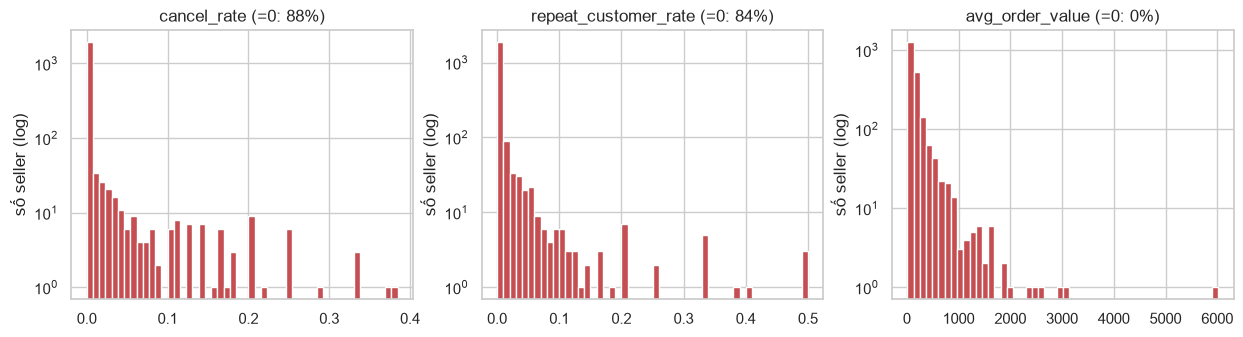

Pearson log1p(avg_order_value) & log1p(price_index): 0.881


In [6]:
display(profile_stats(df, DROPPED)[["mean", "median", "max", "skew", "zero_share", "mode_share"]].round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, DROPPED):
    a.hist(df[c], bins=50, color="#C44E52")
    a.set(title=f"{c} (=0: {(df[c] == 0).mean():.0%})", yscale="log", ylabel="số seller (log)")
save(fig, "eda_dropped_features.png")
r = np.corrcoef(np.log1p(df["avg_order_value"]), np.log1p(df["price_index"]))[0, 1]
print(f"Pearson log1p(avg_order_value) & log1p(price_index): {r:.3f}")

### 2.4. Phân phối trước và sau `log1p`

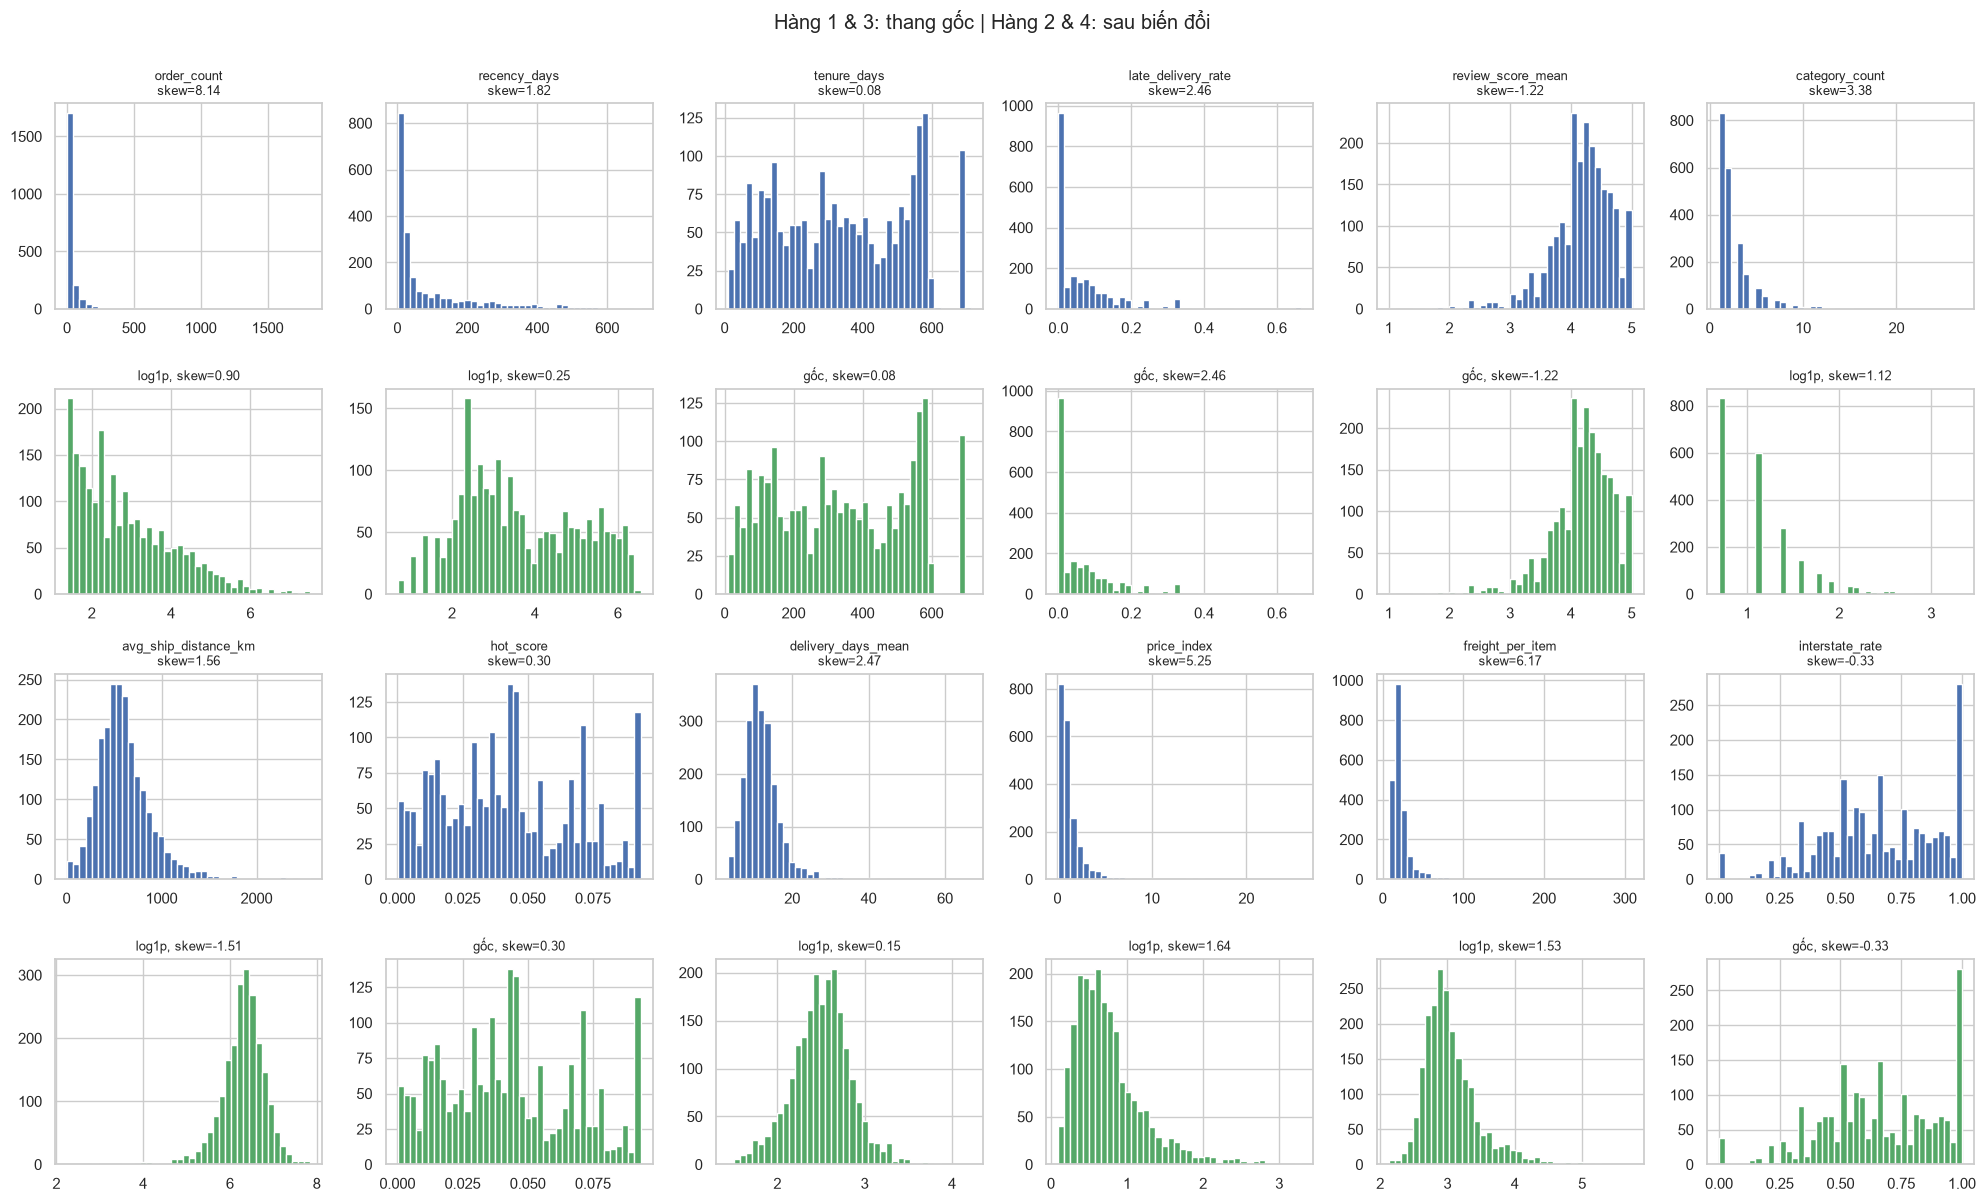

In [7]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12))
for i, c in enumerate(FEATURES):
    a_raw, a_tr = axes[(i // 6) * 2, i % 6], axes[(i // 6) * 2 + 1, i % 6]
    s = df[c].dropna()
    t = np.log1p(s) if c in LOG1P else s
    a_raw.hist(s, bins=40, color="#4C72B0"); a_raw.set_title(f"{c}\nskew={s.skew():.2f}", fontsize=9)
    a_tr.hist(t, bins=40, color="#55A868"); a_tr.set_title(("log1p, " if c in LOG1P else "gốc, ") + f"skew={t.skew():.2f}", fontsize=9)
fig.suptitle("Hàng 1 & 3: thang gốc | Hàng 2 & 4: sau biến đổi", y=1.0)
fig.tight_layout()
save(fig, "eda_distributions.png")

### 2.5. Tương quan giữa các đặc trưng

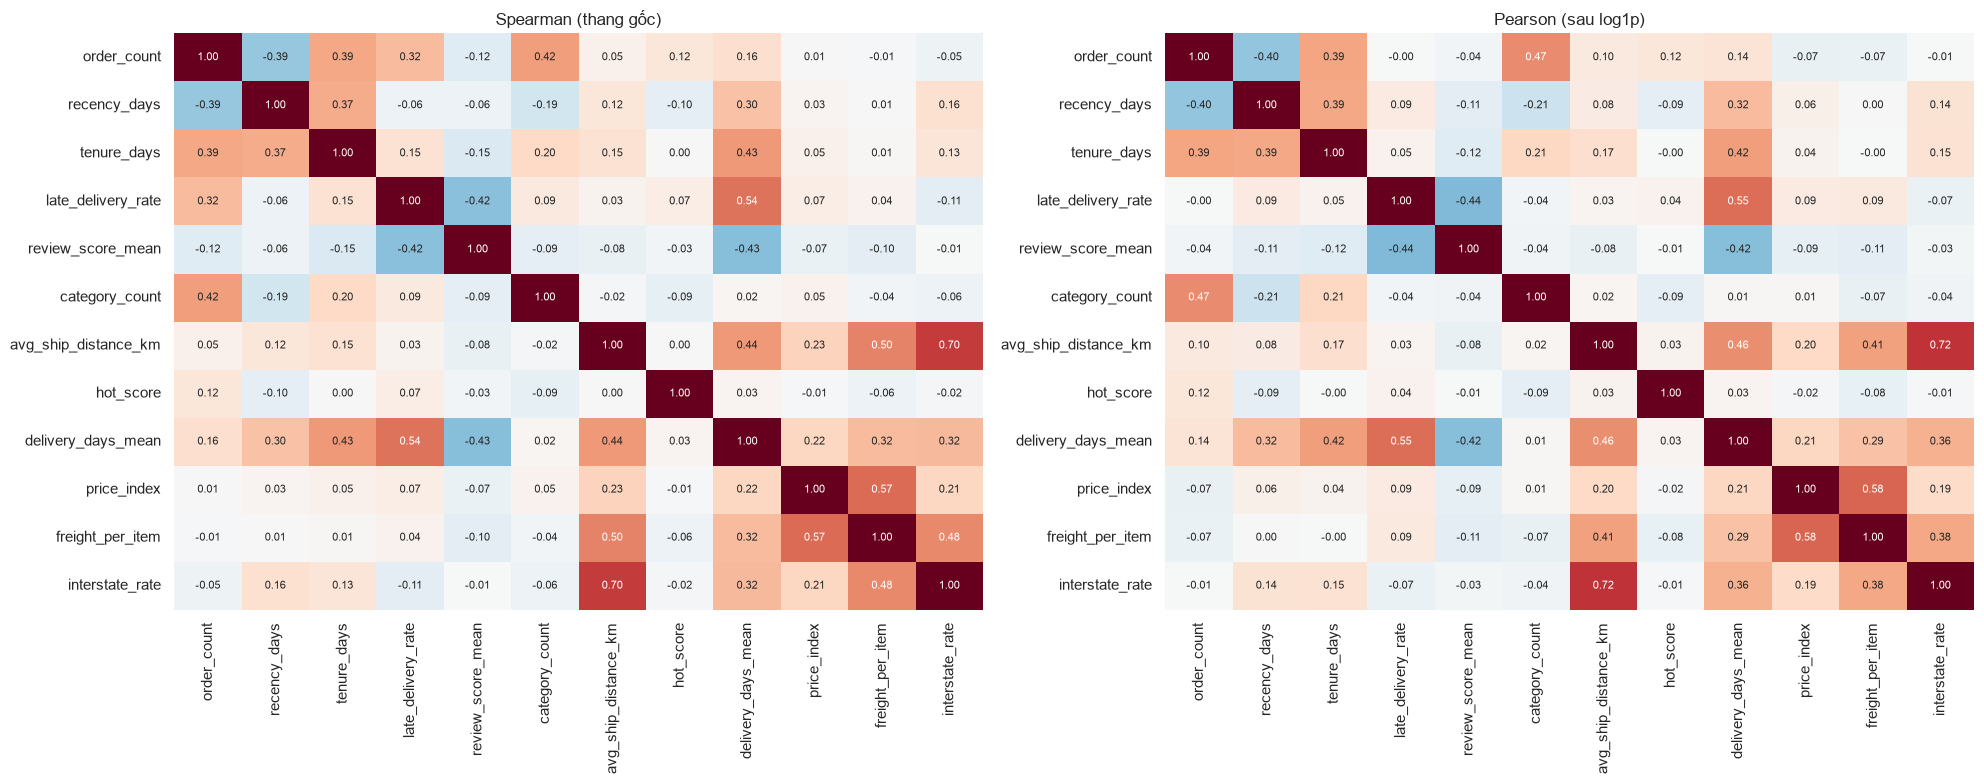

,feature_a,feature_b,pearson
1,avg_ship_distance_km,interstate_rate,0.722
2,price_index,freight_per_item,0.584
0,late_delivery_rate,delivery_days_mean,0.555


In [8]:
T = df[FEATURES].astype(float).fillna(df[FEATURES].median())
for c in LOG1P:
    T[c] = np.log1p(T[c])

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
for a, (name, m) in zip(ax, [("Spearman (thang gốc)", df[FEATURES].corr("spearman")), ("Pearson (sau log1p)", T.corr())]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=a, cbar=False, annot_kws={"size": 8})
    a.set_title(name)
fig.tight_layout()
save(fig, "eda_correlation.png")

pc = T.corr()
pairs = pd.DataFrame([(a, b, pc.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:] if abs(pc.loc[a, b]) >= 0.5],
                     columns=["feature_a", "feature_b", "pearson"]).sort_values("pearson", key=abs, ascending=False)
assert (pairs["pearson"].abs() < 0.75).all(), "Có cặp tương quan >= 0.75"
pairs.round(3)

Giữ các cặp |r| ≥ 0,5 (đều < 0,75) vì mang ý nghĩa nghiệp vụ khác nhau.

### 2.6. Sàng lọc đặc trưng chưa dùng

In [9]:
cands = [c for c in df.select_dtypes("number").columns if c not in set(FEATURES) | {"model_eligible", "has_marketing_profile", "is_sp"}]
sp = df[FEATURES + cands].corr("spearman")
rows = []
for c in cands:
    s = df[c].astype(float)
    if s.nunique(dropna=True) <= 1:
        rows.append((c, s.isna().mean(), np.nan, np.nan, np.nan, "", "hằng số"))
        continue
    r = sp.loc[c, FEATURES].abs()
    mode = s.round(6).value_counts(normalize=True).iloc[0]
    why = f"trùng ý với {r.idxmax()}" if r.max() >= 0.75 else ("lệch / lặp nhiều" if mode >= 0.5 or abs(s.skew()) > 5 else "ứng viên")
    rows.append((c, s.isna().mean(), s.skew(), mode, r.max(), r.idxmax(), why))

screen = pd.DataFrame(rows, columns=["feature", "missing", "skew", "mode_share", "max_abs_spearman", "closest", "phan_loai"])
screen = screen.sort_values(["phan_loai", "max_abs_spearman"], ascending=[True, False])
screen.to_csv(OUT / "unused_feature_screening.csv", index=False)
print(screen["phan_loai"].str.replace(r"trùng ý với .*", "trùng ý", regex=True).value_counts().to_string())
screen.round(3)

phan_loai
trùng ý             26
ứng viên            15
lệch / lặp nhiều    14
hằng số              2


,feature,missing,skew,mode_share,max_abs_spearman,closest,phan_loai
42,distance_coverage,0.000,NaN,NaN,NaN,,hằng số
56,declared_monthly_revenue,0.883,NaN,NaN,NaN,,hằng số
33,delivery_days_std,0.000,5.136,0.000,0.720,delivery_days_mean,lệch / lặp nhiều
21,sales_growth,0.381,8.680,0.190,0.591,recency_days,lệch / lặp nhiều
25,market_share_in_cat,0.000,6.385,0.002,0.578,order_count,lệch / lặp nhiều
9,review_coverage,0.000,-7.303,0.825,0.443,order_count,lệch / lặp nhiều
46,repeat_customer_rate,0.000,8.764,0.841,0.419,order_count,lệch / lặp nhiều
50,voucher_rate,0.000,3.409,0.543,0.418,order_count,lệch / lặp nhiều
12,undelivered_rate,0.000,4.733,0.713,0.394,order_count,lệch / lặp nhiều
35,days_late_mean,0.439,5.395,0.060,0.325,delivery_days_mean,lệch / lặp nhiều


### 2.7. Biến phân loại (chỉ dùng mô tả cụm)

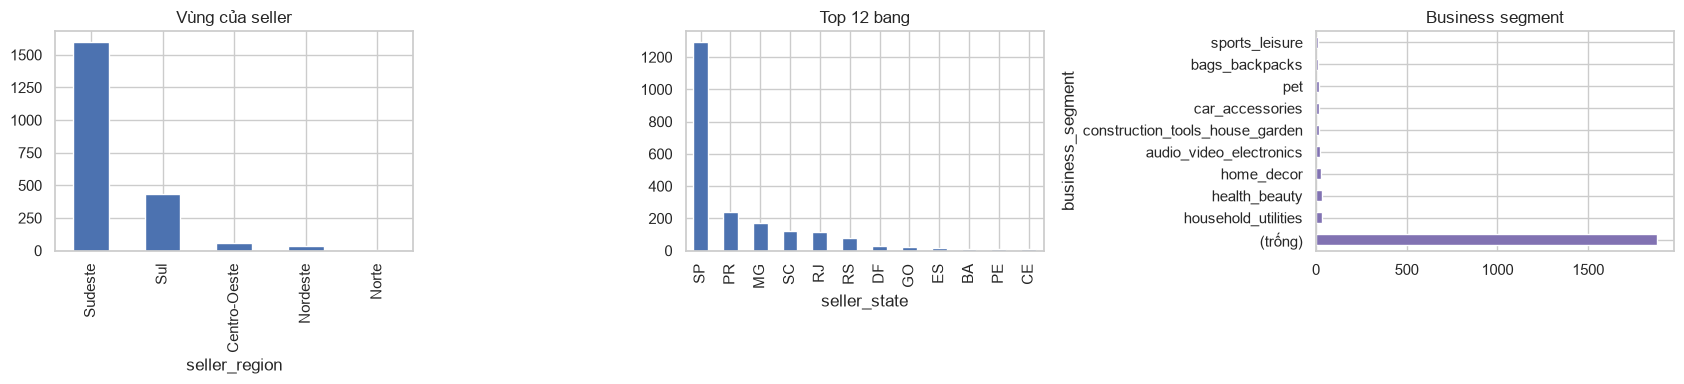

SP chiếm 60.8% | Có marketing profile: 11.7%


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df["seller_region"].value_counts().plot.bar(ax=ax[0], color="#4C72B0", title="Vùng của seller")
df["seller_state"].value_counts().head(12).plot.bar(ax=ax[1], color="#4C72B0", title="Top 12 bang")
df["business_segment"].fillna("(trống)").value_counts().head(10).plot.barh(ax=ax[2], color="#8172B2", title="Business segment")
fig.tight_layout()
save(fig, "eda_categorical.png")
print(f"SP chiếm {(df.seller_state == 'SP').mean():.1%} | Có marketing profile: {df.has_marketing_profile.mean():.1%}")

### 2.8. Pairplot một số cặp đặc trưng

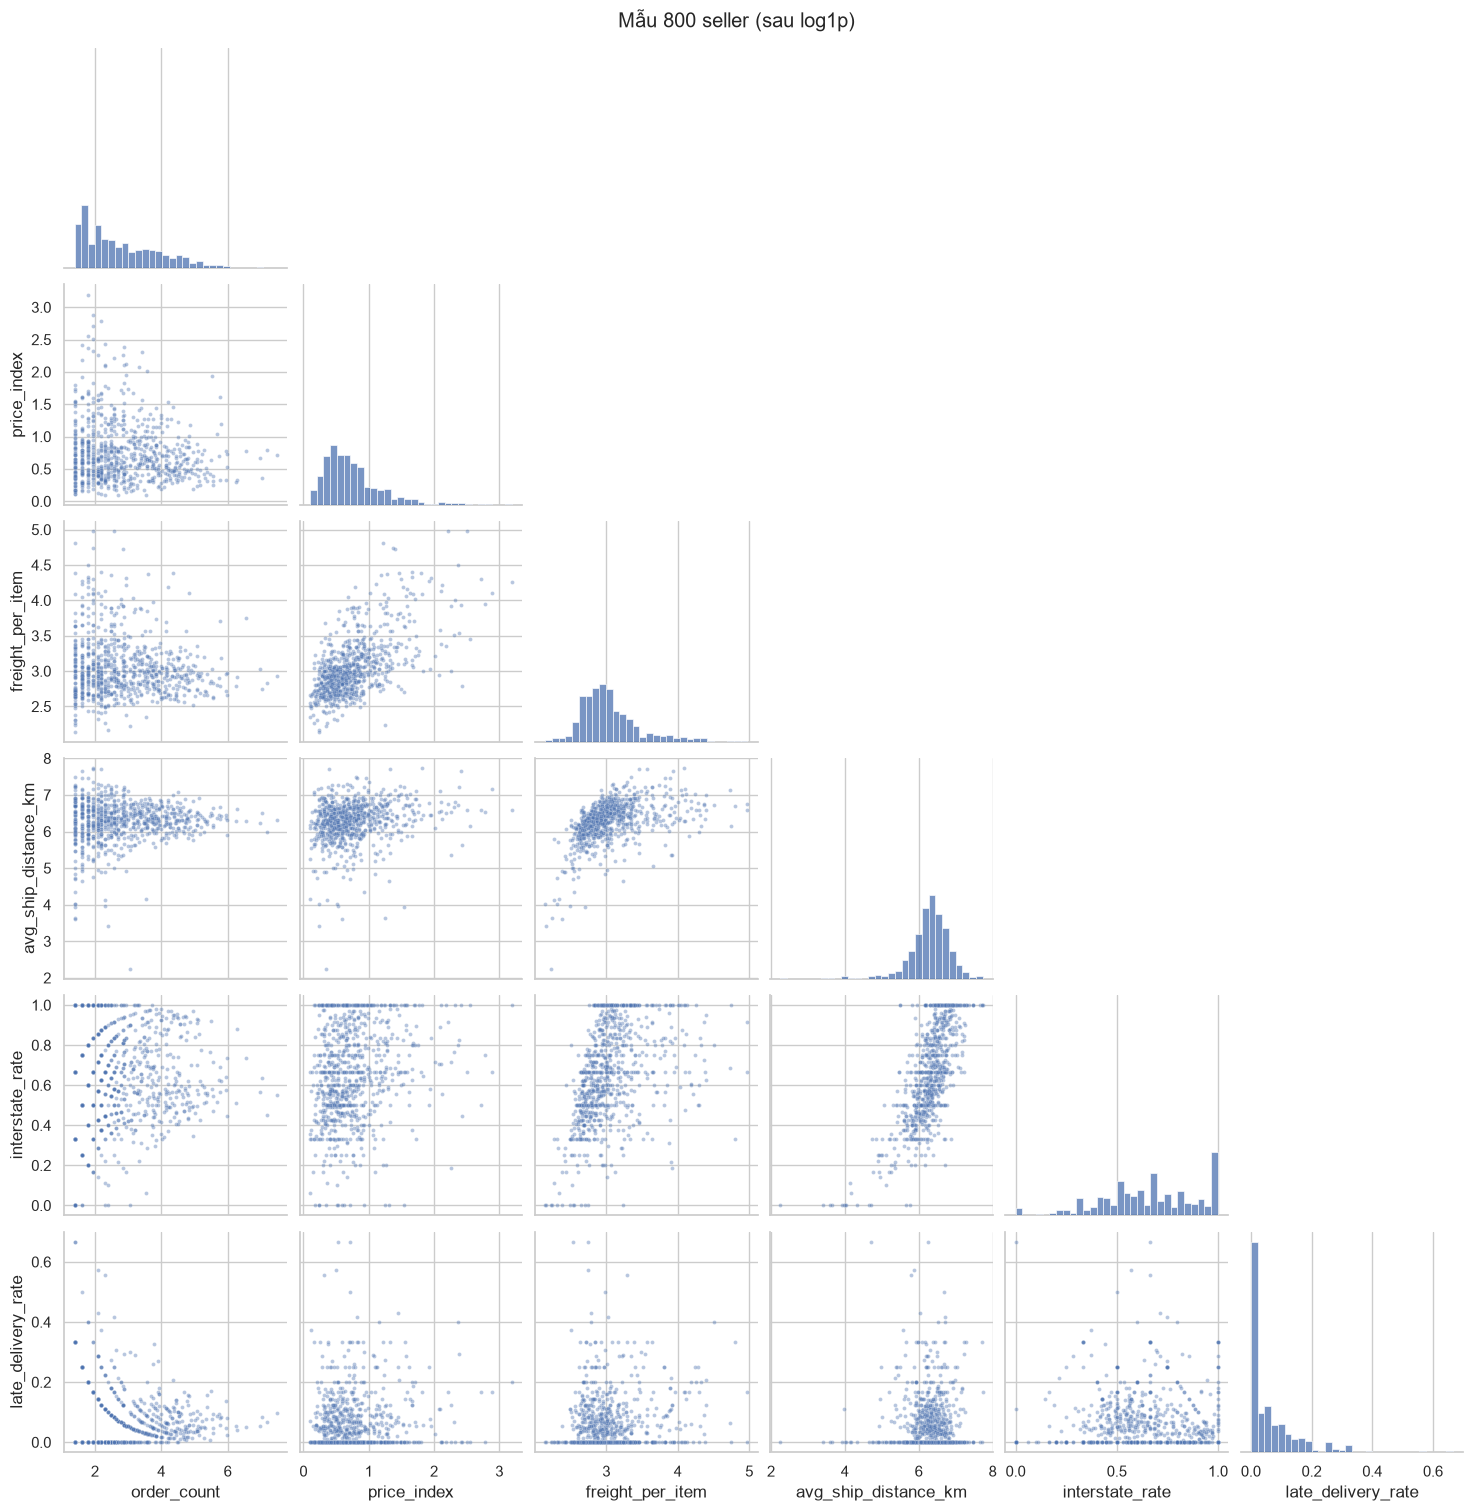

In [11]:
pp = T[["order_count", "price_index", "freight_per_item", "avg_ship_distance_km", "interstate_rate", "late_delivery_rate"]]
g = sns.pairplot(pp.sample(800, random_state=RANDOM_STATE), corner=True, plot_kws={"s": 8, "alpha": 0.4}, diag_kws={"bins": 30})
g.fig.suptitle("Mẫu 800 seller (sau log1p)", y=1.01)
save(g.fig, "eda_pairplot.png")

## 3. Tiền xử lý
Điền thiếu bằng **median** → **`log1p`** (7 cột lệch phải) → **`StandardScaler`** (12 cột). Giữ nguyên ngoại lệ để DBSCAN nhận diện.

In [12]:
Xraw = df[FEATURES].astype(float)
medians = Xraw.median()
Xt = Xraw.fillna(medians)
for c in LOG1P:
    assert (Xt[c] >= 0).all(), c
    Xt[c] = np.log1p(Xt[c])

scaler = StandardScaler().fit(Xt)
X = scaler.transform(Xt)
assert np.isfinite(X).all() and np.allclose(X.mean(0), 0, atol=1e-9) and np.allclose(X.std(0), 1, atol=1e-9)

pd.DataFrame(X, columns=FEATURES).assign(seller_id=df["seller_id"])[["seller_id"] + FEATURES].to_csv(OUT / "model_input.csv", index=False)
prep = {"features": FEATURES, "log1p": LOG1P, "dropped_from_v2": DROPPED, "n_sellers": len(df),
        "missing_filled": Xraw.isna().sum().to_dict(), "median": medians.to_dict(),
        "scaler_mean": dict(zip(FEATURES, scaler.mean_)), "scaler_scale": dict(zip(FEATURES, scaler.scale_)),
        "random_state": RANDOM_STATE, "versions": versions}
(OUT / "preprocessing.json").write_text(json.dumps(prep, indent=2, ensure_ascii=False), encoding="utf-8")
print("Ma trận X:", X.shape, "| Ô điền median:", int(Xraw.isna().sum().sum()))

Ma trận X: (2129, 12) | Ô điền median: 0


In [13]:
def scores(labels):
    labels = np.asarray(labels)
    m = labels >= 0
    k = len(np.unique(labels[m]))
    out = {"n_clusters": k, "noise_share": 1 - m.mean()}
    if k < 2:
        return out | {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan, "min_cluster_share": np.nan}
    sizes = np.unique(labels[m], return_counts=True)[1]
    return out | {"silhouette": silhouette_score(X[m], labels[m]), "davies_bouldin": davies_bouldin_score(X[m], labels[m]),
                  "calinski_harabasz": calinski_harabasz_score(X[m], labels[m]), "min_cluster_share": sizes.min() / len(labels)}

def relabel(labels):
    labels = np.asarray(labels)
    sales = pd.Series(df["total_sales"].to_numpy()).groupby(labels).sum().drop(-1, errors="ignore")
    order = {old: new for new, old in enumerate(sales.sort_values(ascending=False).index)}
    return np.array([order.get(l, -1) for l in labels])

## 4. K-Means
Quét `k = 2..10` (`n_init=30`). Chọn `k` theo Silhouette cao nhất (cụm nhỏ nhất ≥ 2% cohort) và đối chiếu Elbow.

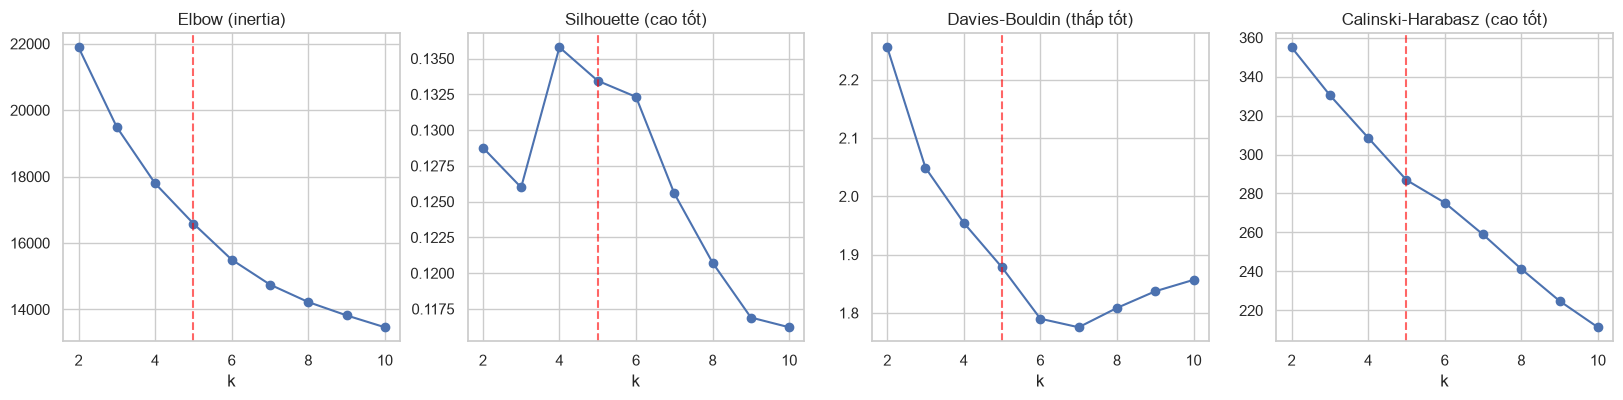

Quy tắc gợi ý k = 4 | Dùng K_KMEANS = 5


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
0,2,21893.5356,0.1288,2.2556,355.0411,0.3969
1,3,19489.3004,0.1260,2.0488,330.4601,0.2781
2,4,17794.7283,0.1358,1.9544,308.6252,0.1292
3,5,16586.1373,0.1334,1.8779,286.9112,0.0996
4,6,15499.8101,0.1323,1.7900,275.2589,0.0958
5,7,14748.8559,0.1256,1.7753,258.9555,0.0836
6,8,14223.0269,0.1207,1.8085,241.2614,0.0780
7,9,13821.4407,0.1169,1.8371,224.8346,0.0324
8,10,13463.3424,0.1162,1.8566,211.3343,0.0315


In [14]:
km_models = {k: KMeans(k, n_init=30, random_state=RANDOM_STATE).fit(X) for k in K_RANGE}
km_metrics = pd.DataFrame([{"k": k, "inertia": m.inertia_} | scores(m.labels_) for k, m in km_models.items()]).drop(columns=["n_clusters", "noise_share"])
km_metrics.to_csv(OUT / "kmeans_metrics.csv", index=False)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, col, title in zip(ax, ["inertia", "silhouette", "davies_bouldin", "calinski_harabasz"],
                         ["Elbow (inertia)", "Silhouette (cao tốt)", "Davies-Bouldin (thấp tốt)", "Calinski-Harabasz (cao tốt)"]):
    a.plot(km_metrics["k"], km_metrics[col], "o-"); a.axvline(K_KMEANS, color="red", ls="--", alpha=0.6)
    a.set(title=title, xlabel="k")
save(fig, "kmeans_selection.png")

ok = km_metrics[km_metrics["min_cluster_share"] >= MIN_SHARE]
k_rule = int(ok.loc[ok["silhouette"].idxmax(), "k"])
print(f"Quy tắc gợi ý k = {k_rule} | Dùng K_KMEANS = {K_KMEANS}")
km_metrics.round(4)

Ổn định 10 seed: ARI min=0.8684, mean=0.9356 | Kích thước cụm: [532, 449, 471, 212, 465]


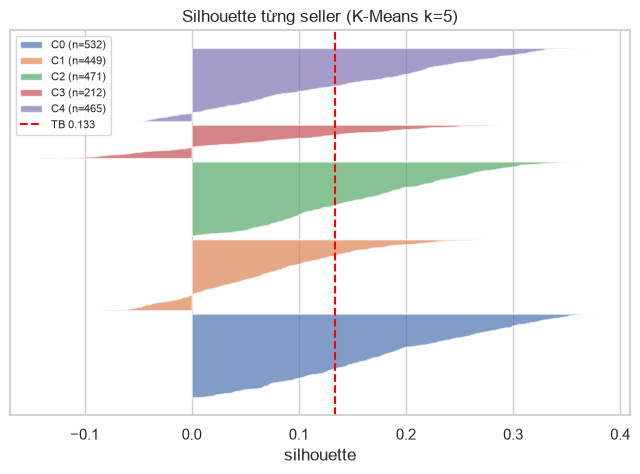

Tỷ lệ silhouette âm: {0: 0.006, 1: 0.225, 2: 0.004, 3: 0.34, 4: 0.118}


In [15]:
km = km_models[K_KMEANS]
km_labels = relabel(km.labels_)
aris = [adjusted_rand_score(km.labels_, KMeans(K_KMEANS, n_init=30, random_state=s).fit_predict(X)) for s in range(10)]
print(f"Ổn định 10 seed: ARI min={min(aris):.4f}, mean={np.mean(aris):.4f} | Kích thước cụm: {np.bincount(km_labels).tolist()}")

sil = silhouette_samples(X, km_labels)
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 0
for c in range(K_KMEANS):
    v = np.sort(sil[km_labels == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7, label=f"C{c} (n={len(v)})")
    y0 += len(v) + 20
ax.axvline(sil.mean(), color="red", ls="--", label=f"TB {sil.mean():.3f}")
ax.set(title=f"Silhouette từng seller (K-Means k={K_KMEANS})", xlabel="silhouette", yticks=[]); ax.legend(fontsize=8)
save(fig, "kmeans_silhouette_samples.png")
print("Tỷ lệ silhouette âm:", pd.Series(sil < 0).groupby(km_labels).mean().round(3).to_dict())

## 5. GMM
Quét `k = 2..10` với 4 kiểu covariance (`n_init=5`), chọn mô hình có **BIC nhỏ nhất** (cụm nhỏ nhất ≥ 2%).

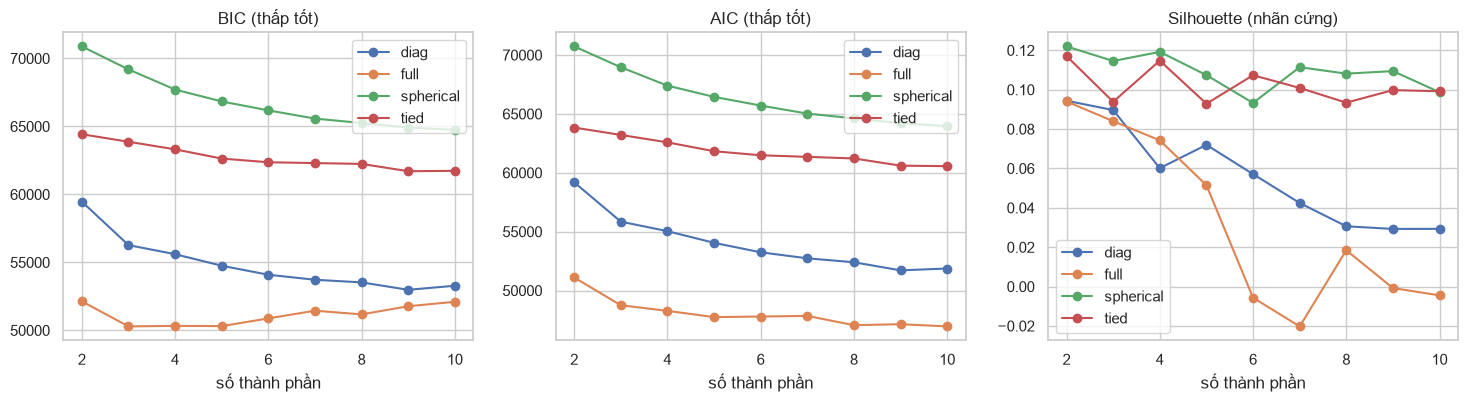

Best BIC (cụm >= 2%): full, k=3


,covariance,k,bic,aic,mean_max_proba,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
1,full,3,50291.1309,48750.6840,0.9704,3,0.0840,2.5677,196.1248,0.2062
3,full,5,50314.0038,47742.8167,0.9277,5,0.0515,3.0412,144.6834,0.1254
2,full,4,50330.0876,48274.2706,0.9593,4,0.0743,2.6386,164.7737,0.1109
4,full,6,50879.3501,47792.7929,0.9493,6,-0.0057,2.6613,118.8785,0.0178
6,full,8,51175.1344,47057.8371,0.9210,8,0.0184,2.6539,119.5862,0.0493
5,full,7,51446.4830,47844.5557,0.9399,7,-0.0203,2.5292,109.7602,0.0099
7,full,9,51774.5940,47141.9265,0.9284,9,-0.0008,2.4897,108.8776,0.0132
8,full,10,52102.4536,46954.4160,0.9307,10,-0.0045,2.5760,102.5526,0.0070
0,full,2,52136.1343,51111.0575,0.9984,2,0.0940,2.9448,217.8663,0.4382
25,diag,9,52982.7096,51714.1063,0.9115,9,0.0293,2.4890,133.5936,0.0338


In [16]:
gm_rows, gm_models = [], {}
for cov in ["full", "tied", "diag", "spherical"]:
    for k in K_RANGE:
        g = GaussianMixture(k, covariance_type=cov, n_init=5, random_state=RANDOM_STATE).fit(X)
        gm_models[(cov, k)] = g
        gm_rows.append({"covariance": cov, "k": k, "bic": g.bic(X), "aic": g.aic(X),
                        "mean_max_proba": g.predict_proba(X).max(1).mean()} | scores(g.predict(X)))
gm_metrics = pd.DataFrame(gm_rows).drop(columns=["noise_share"])
gm_metrics.to_csv(OUT / "gmm_metrics.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for cov, sub in gm_metrics.groupby("covariance"):
    for a, col in zip(ax, ["bic", "aic", "silhouette"]):
        a.plot(sub["k"], sub[col], "o-", label=cov)
for a, t in zip(ax, ["BIC (thấp tốt)", "AIC (thấp tốt)", "Silhouette (nhãn cứng)"]):
    a.set(title=t, xlabel="số thành phần"); a.legend()
save(fig, "gmm_selection.png")

best = gm_metrics[gm_metrics["min_cluster_share"] >= MIN_SHARE].sort_values("bic").iloc[0]
GMM_COV, GMM_K = best["covariance"], int(best["k"])
print(f"Best BIC (cụm >= 2%): {GMM_COV}, k={GMM_K}")
gm_metrics.sort_values("bic").head(10).round(4)

In [17]:
gmm = gm_models[(GMM_COV, GMM_K)]
gmm_labels = relabel(gmm.predict(X))
proba = gmm.predict_proba(X).max(1)
print(f"Kích thước cụm: {np.bincount(gmm_labels).tolist()} | Proba trung vị: {np.median(proba):.3f} | <0.6: {(proba < 0.6).mean():.1%}")

gm5 = gm_metrics[gm_metrics.k == K_KMEANS].sort_values("bic")
display(gm5.round(4))
gmm5_labels = relabel(gm_models[(gm5.iloc[0]["covariance"], K_KMEANS)].predict(X))
print(f"GMM k={K_KMEANS} ({gm5.iloc[0]['covariance']}): {np.bincount(gmm5_labels).tolist()} | ARI vs K-Means: {adjusted_rand_score(km_labels, gmm5_labels):.3f}")

Kích thước cụm: [759, 439, 931] | Proba trung vị: 1.000 | <0.6: 1.7%


,covariance,k,bic,aic,mean_max_proba,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
3,full,5,50314.0038,47742.8167,0.9277,5,0.0515,3.0412,144.6834,0.1254
21,diag,5,54753.3772,54051.1147,0.9470,5,0.0720,2.3141,191.6279,0.0930
12,tied,5,62634.4777,61830.2738,0.9181,5,0.0929,1.9712,175.2878,0.0146
30,spherical,5,66835.6467,66444.8716,0.8799,5,0.1074,2.0278,266.6109,0.1630


GMM k=5 (full): [627, 267, 537, 303, 395] | ARI vs K-Means: 0.242


## 6. DBSCAN
`min_samples = 2 × số chiều = 24`; chọn `eps` tại điểm khuỷu đồ thị k-distance và quét lưới độ nhạy.

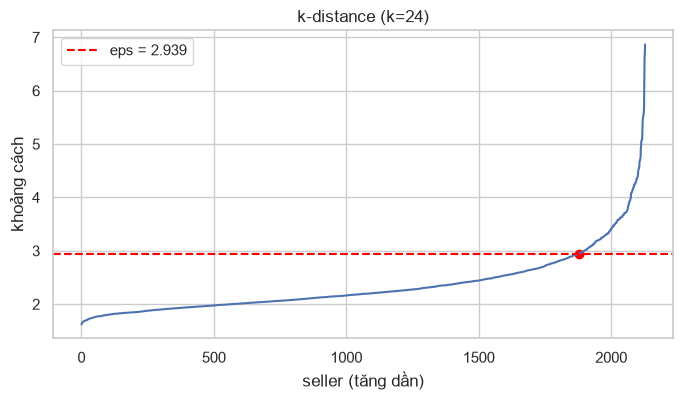

,min_samples,eps,eps_factor,cluster_sizes,n_clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
0,12,2.0575,0.7,[1717],1,0.1935,NaN,NaN,NaN,NaN
1,12,2.3514,0.8,[1903],1,0.1062,NaN,NaN,NaN,NaN
2,12,2.6454,0.9,[2021],1,0.0507,NaN,NaN,NaN,NaN
3,12,2.9393,1.0,[2075],1,0.0254,NaN,NaN,NaN,NaN
4,12,3.2332,1.1,[2101],1,0.0132,NaN,NaN,NaN,NaN
5,12,3.5271,1.2,[2112],1,0.0080,NaN,NaN,NaN,NaN
6,12,4.1150,1.4,[2122],1,0.0033,NaN,NaN,NaN,NaN
7,24,2.0575,0.7,[1587],1,0.2546,NaN,NaN,NaN,NaN
8,24,2.3514,0.8,[1856],1,0.1282,NaN,NaN,NaN,NaN
9,24,2.6454,0.9,[1987],1,0.0667,NaN,NaN,NaN,NaN


In [18]:
MIN_SAMPLES = 2 * X.shape[1]
dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
i = np.arange(len(dist))
knee = int(np.argmax(dist[0] + (dist[-1] - dist[0]) * i / (len(dist) - 1) - dist))
EPS = float(dist[knee])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(i, dist); ax.axhline(EPS, color="red", ls="--", label=f"eps = {EPS:.3f}"); ax.scatter([knee], [EPS], color="red")
ax.set(title=f"k-distance (k={MIN_SAMPLES})", xlabel="seller (tăng dần)", ylabel="khoảng cách"); ax.legend()
save(fig, "dbscan_kdistance.png")

db_rows = []
for ms in [12, MIN_SAMPLES, 36]:
    for f in [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.4]:
        lab = DBSCAN(eps=EPS * f, min_samples=ms).fit_predict(X)
        db_rows.append({"min_samples": ms, "eps": EPS * f, "eps_factor": f,
                        "cluster_sizes": np.unique(lab[lab >= 0], return_counts=True)[1].tolist()} | scores(lab))
db_metrics = pd.DataFrame(db_rows)
db_metrics.to_csv(OUT / "dbscan_metrics.csv", index=False)
db_metrics.round(4)

In [19]:
db_labels = relabel(DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X))
print(f"DBSCAN eps={EPS:.3f}, ms={MIN_SAMPLES}: cụm {np.bincount(db_labels[db_labels >= 0]).tolist()} | nhiễu {(db_labels == -1).sum()} ({(db_labels == -1).mean():.1%})")

noise = pd.DataFrame({"nhom": np.where(db_labels == -1, "nhiễu", "trong cụm")}).join(df[FEATURES + ["total_sales"]])
cmp = noise.groupby("nhom")[FEATURES].median().T
cmp["chenh_lech_z"] = pd.DataFrame(X, columns=FEATURES).groupby(noise["nhom"]).mean().T.diff(axis=1).iloc[:, -1]
print("Tỷ trọng doanh số nhóm nhiễu:", round(noise.loc[noise.nhom == "nhiễu", "total_sales"].sum() / noise.total_sales.sum(), 4))
cmp.round(3)

DBSCAN eps=2.939, ms=24: cụm [2060] | nhiễu 69 (3.2%)
Tỷ trọng doanh số nhóm nhiễu: 0.0263


nhom,nhiễu,trong cụm,chenh_lech_z
order_count,4.000,13.000,0.922
recency_days,112.000,27.000,-0.600
tenure_days,276.000,329.000,0.162
late_delivery_rate,0.200,0.032,-1.866
review_score_mean,3.273,4.250,1.890
category_count,1.000,2.000,0.620
avg_ship_distance_km,520.614,564.529,0.684
hot_score,0.044,0.042,0.045
delivery_days_mean,16.254,11.274,-0.990
price_index,2.462,0.914,-1.475


## 7. So sánh 3 thuật toán
*Lưu ý: metric của DBSCAN chỉ tính trên các điểm không phải nhiễu.*

In [20]:
models = {f"K-Means k={K_KMEANS}": km_labels, f"GMM {GMM_COV} k={GMM_K}": gmm_labels,
          f"GMM {gm5.iloc[0]['covariance']} k={K_KMEANS}": gmm5_labels, f"DBSCAN eps={EPS:.2f}": db_labels}
compare = pd.DataFrame({name: scores(lab) | {"cluster_sizes": np.unique(lab[lab >= 0], return_counts=True)[1].tolist()}
                        for name, lab in models.items()}).T
compare.to_csv(OUT / "model_comparison.csv")
display(compare)

names = list(models)
ari = pd.DataFrame([[adjusted_rand_score(models[a], models[b]) for b in names] for a in names], index=names, columns=names)
print("ARI giữa các mô hình:")
ari.round(3)

,n_clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,cluster_sizes
K-Means k=5,5,0.0,0.133444,1.877867,286.911234,0.099577,"[532, 449, 471, 212, 465]"
GMM full k=3,3,0.0,0.083994,2.567734,196.124784,0.2062,"[759, 439, 931]"
GMM full k=5,5,0.0,0.051453,3.041191,144.683378,0.125411,"[627, 267, 537, 303, 395]"
DBSCAN eps=2.94,1,0.03241,NaN,NaN,NaN,NaN,[2060]


ARI giữa các mô hình:


,K-Means k=5,GMM full k=3,GMM full k=5,DBSCAN eps=2.94
K-Means k=5,1.000,0.239,0.242,0.012
GMM full k=3,0.239,1.000,0.610,0.016
GMM full k=5,0.242,0.610,1.000,0.012
DBSCAN eps=2.94,0.012,0.016,0.012,1.000


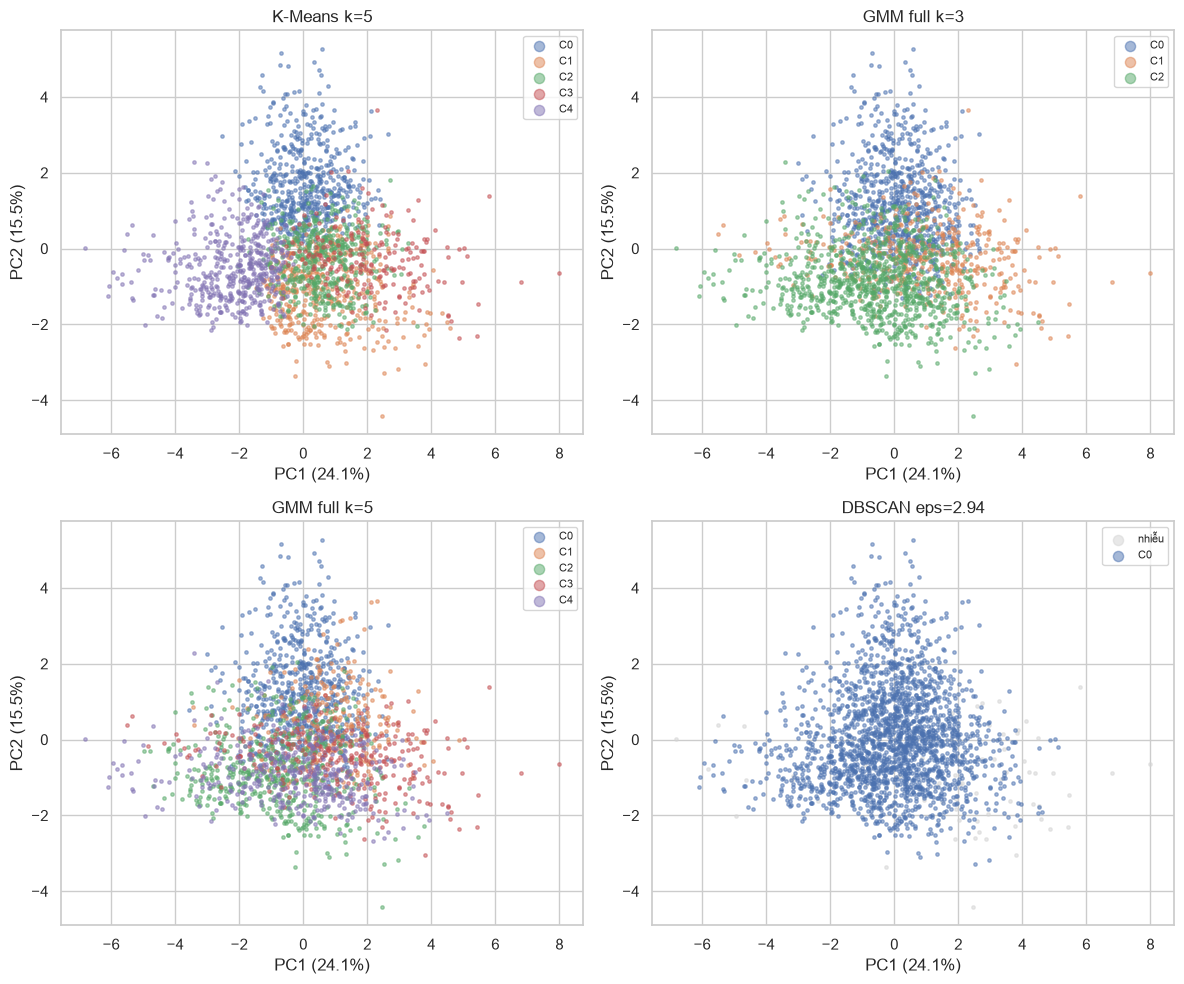

PCA 2D giữ 39.5% phương sai:


,PC1,PC2
review_score_mean,-0.249,-0.135
hot_score,-0.009,0.094
category_count,0.004,0.511
order_count,0.047,0.627
recency_days,0.208,-0.222
late_delivery_rate,0.241,0.094
tenure_days,0.257,0.366
price_index,0.281,-0.187
freight_per_item,0.357,-0.235
interstate_rate,0.385,-0.127


In [21]:
pca = PCA(2, random_state=RANDOM_STATE).fit(X)
P, ev = pca.transform(X), pca.explained_variance_ratio_
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for a, (name, lab) in zip(ax.flat, models.items()):
    for c in np.unique(lab):
        m = lab == c
        a.scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, label="nhiễu" if c == -1 else f"C{c}", c="lightgray" if c == -1 else None)
    a.set(title=name, xlabel=f"PC1 ({ev[0]:.1%})", ylabel=f"PC2 ({ev[1]:.1%})"); a.legend(markerscale=3, fontsize=8)
fig.tight_layout()
save(fig, "pca_3_methods.png")
print(f"PCA 2D giữ {ev.sum():.1%} phương sai:")
pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(3).sort_values("PC1")

## 8. Profile cụm K-Means (k=5)

In [22]:
P_df = df.assign(cluster=km_labels)
gb = P_df.groupby("cluster")
prof = gb[FEATURES + DESCRIBE].median()
prof.insert(0, "sales_share", gb["total_sales"].sum() / P_df["total_sales"].sum())
prof.insert(0, "n_sellers", gb.size())
prof[["late_delivery_rate_mean", "review_score_mean_mean", "cancel_rate_mean"]] = gb[["late_delivery_rate", "review_score_mean", "cancel_rate"]].mean()
prof["pct_sp"] = gb["seller_state"].apply(lambda s: (s == "SP").mean())
prof["top_region"] = gb["seller_region"].agg(lambda s: s.value_counts().index[0])
prof.to_csv(OUT / "kmeans_cluster_profile.csv")
prof.T

cluster,0,1,2,3,4
n_sellers,532,449,471,212,465
sales_share,0.672742,0.17322,0.073453,0.041542,0.039043
order_count,77.0,10.0,10.0,7.0,7.0
recency_days,12.0,20.0,220.0,119.0,18.0
tenure_days,479.5,173.0,505.0,324.0,139.0
late_delivery_rate,0.062008,0.0,0.0,0.25,0.0
review_score_mean,4.167275,4.333333,4.272727,3.571429,4.444444
category_count,3.0,2.0,2.0,1.0,2.0
avg_ship_distance_km,560.188229,714.565872,637.313755,661.24163,340.137679
hot_score,0.046201,0.039941,0.035135,0.038902,0.04379


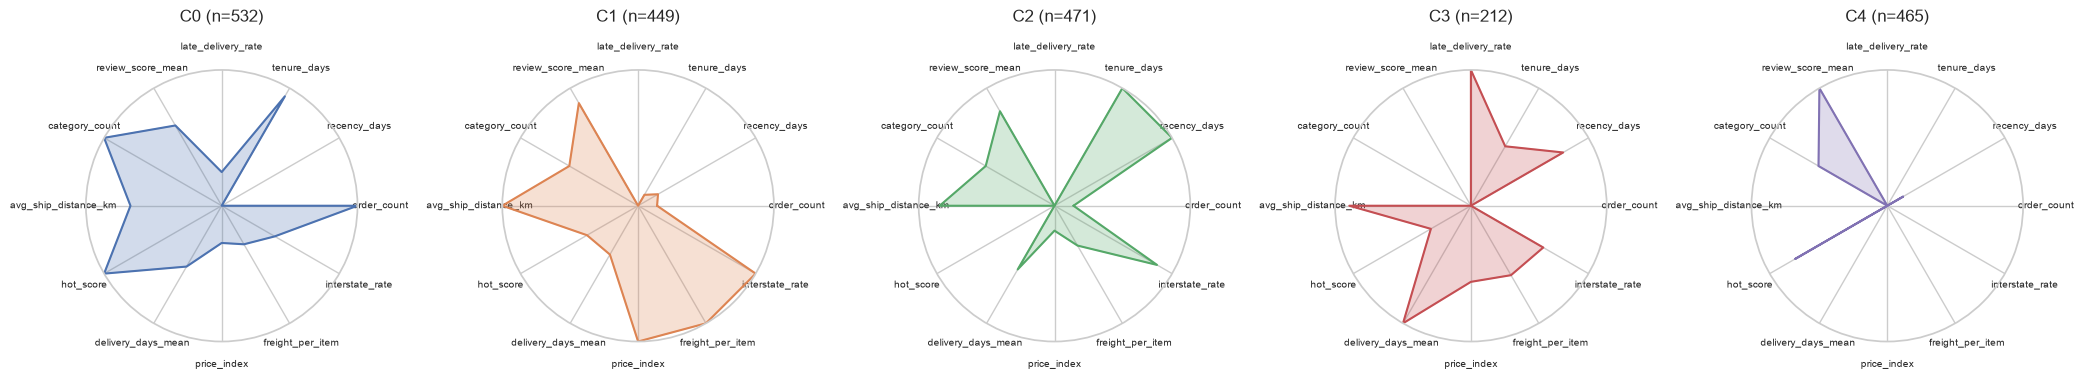

In [23]:
rad = pd.DataFrame(Xt.to_numpy(), columns=FEATURES).groupby(km_labels).median()
rad = (rad - rad.min()) / (rad.max() - rad.min()).replace(0, 1)
ang = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist()
fig, axes = plt.subplots(1, K_KMEANS, figsize=(4.2 * K_KMEANS, 4.5), subplot_kw={"polar": True})
for a, (c, row) in zip(axes, rad.iterrows()):
    v = row.tolist()
    a.plot(ang + ang[:1], v + v[:1], color=f"C{c}"); a.fill(ang + ang[:1], v + v[:1], alpha=0.25, color=f"C{c}")
    a.set_xticks(ang); a.set_xticklabels(FEATURES, fontsize=7); a.set_yticks([]); a.set_ylim(0, 1)
    a.set_title(f"C{c} (n={int((km_labels == c).sum())})", pad=15)
fig.tight_layout()
save(fig, "kmeans_radar.png")

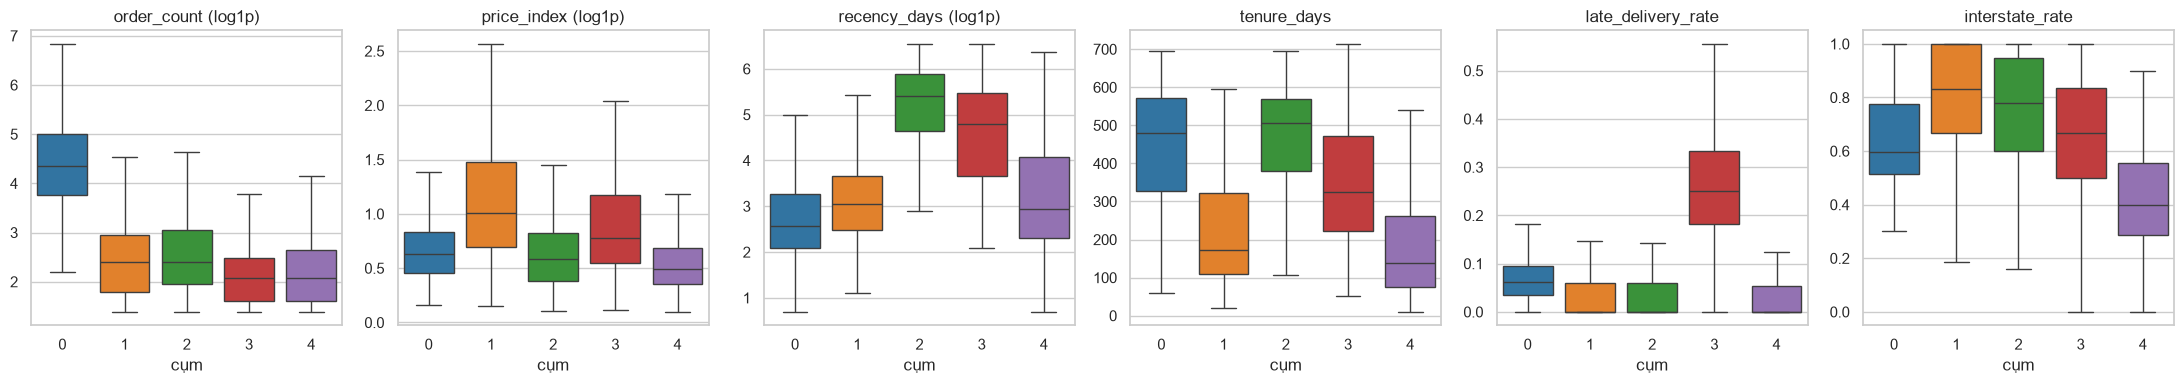

In [24]:
key = ["order_count", "price_index", "recency_days", "tenure_days", "late_delivery_rate", "interstate_rate"]
fig, axes = plt.subplots(1, len(key), figsize=(22, 4))
for a, c in zip(axes, key):
    sns.boxplot(x=km_labels, y=Xt[c], ax=a, showfliers=False, hue=km_labels, palette="tab10", legend=False)
    a.set(title=c + (" (log1p)" if c in LOG1P else ""), xlabel="cụm", ylabel="")
fig.tight_layout()
save(fig, "kmeans_boxplots.png")

In [25]:
df[["seller_id", "seller_state", "seller_region"]].assign(
    kmeans=km_labels, gmm=gmm_labels, gmm_k5=gmm5_labels, gmm_max_proba=proba, dbscan=db_labels
).to_csv(OUT / "seller_assignments.csv", index=False)

summary = {"n_sellers": len(df), "features": FEATURES,
           "kmeans": {"k": K_KMEANS, "k_by_rule": k_rule} | {k: float(v) for k, v in scores(km_labels).items()},
           "gmm": {"covariance": GMM_COV, "k": GMM_K} | {k: float(v) for k, v in scores(gmm_labels).items()},
           "dbscan": {"eps": EPS, "min_samples": MIN_SAMPLES} | {k: float(v) for k, v in scores(db_labels).items()},
           "pca_explained_variance": ev.tolist(), "kmeans_seed_ari_min": float(min(aris))}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_kdistance.png', 'dbscan_metrics.csv', 'eda_categorical.png', 'eda_cohort.png', 'eda_correlation.png', 'eda_distributions.png', 'eda_dropped_features.png', 'eda_pairplot.png', 'feature_stats_raw.csv', 'gmm_metrics.csv', 'gmm_selection.png', 'kmeans_boxplots.png', 'kmeans_cluster_profile.csv', 'kmeans_metrics.csv', 'kmeans_radar.png', 'kmeans_selection.png', 'kmeans_silhouette_samples.png', 'model_comparison.csv', 'model_input.csv', 'pca_3_methods.png', 'preprocessing.json', 'seller_assignments.csv', 'summary.json', 'unused_feature_screening.csv']


## 9. Kết luận

### 9.1. So sánh 3 thuật toán
| Mô hình | Số cụm | Silhouette | Davies-Bouldin | Calinski-Harabasz | Nhận xét |
|---|---:|---:|---:|---:|---|
| **K-Means (k=5)** | 5 | 0,133 | 1,88 | 287 | Tốt nhất cả 3 metric, cụm cân đối (212–532) |
| GMM full (k=3, min BIC) | 3 | 0,084 | 2,57 | 196 | BIC chọn ít cụm, silhouette thấp |
| GMM full (k=5) | 5 | 0,051 | 3,04 | 145 | Kém hơn K-Means mọi metric (ARI = 0,24) |
| DBSCAN (eps=2,94, ms=24) | 1 + nhiễu | - | - | - | 1 cụm (2.060) + 69 nhiễu (3,2%) |

- **DBSCAN:** Dữ liệu phân bố liên tục nên chỉ gom 1 cụm; hữu ích để lọc 69 seller ngoại lệ (trung vị trễ 0,20, review 3,27, `price_index` 2,46).
- **K-Means (k=5) được chọn:** Silhouette 0,133 phản ánh các vùng phân khúc chồng lấn trên phổ liên tục. Quy tắc gợi ý k=4 (0,1358), chọn k=5 (0,1334) để tách riêng nhóm giá cao giao xa. Ổn định 10 seed: ARI min 0,868, mean 0,936.

### 9.2. Profile 5 cụm (K-Means k=5)
| Cụm | Seller | Doanh số | Đặc điểm chính (trung vị) | Gợi ý tên |
|---|---:|---:|---|---|
| C0 | 532 | 67,3% | 77 đơn, 3 ngành, bán 14 bang, mới bán 12 ngày | Seller chủ lực đa ngành |
| C1 | 449 | 17,3% | `price_index` 1,75, AOV 198 BRL, ship 26,9/món, 83% khác bang | Seller giá cao, giao xa |
| C2 | 471 | 7,3% | 220 ngày chưa có đơn, đã bán 505 ngày | Seller ngưng hoạt động |
| C3 | 212 | 4,2% | Tỷ lệ trễ 0,25 (TB 27%), review TB 3,48, giao 18,5 ngày | Seller giao trễ, review thấp |
| C4 | 465 | 3,9% | Bán 139 ngày, giao 7,6 ngày, 340 km, 84% ở SP | Seller mới, bán gần |

### 9.3. Hạn chế
1. Đặc trưng tính từ CSV thô Kaggle, chưa đọc từ `OlistDW`.
2. Review và ngày giao gắn theo đơn (đơn nhiều seller dùng chung).
3. Phân cụm mô tả dữ liệu lịch sử, không dự báo tương lai.